<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js6/TG6_TP_Regresi_244107020211_NURFINKA_LAILASARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TUGAS PPRAKTIKUM 6 - REGRESI**


---



---
Tugas Praktikum: Multiple Linear Regression dengan Dataset Medical Cost Personal Datasets


---





## **Instruksi Umum:**


1. Anda akan menggunakan dataset "Medical Cost Personal Datasets". Pastikan Anda telah mengunduh dataset ini.

2. Gunakan bahasa pemrograman Python dan library yang sesuai seperti NumPy, Pandas, Matplotlib dan Scikit-Learn untuk melakukan analisis regresi dan SVR.

## **Tugas 1: Multiple Linear Regression**


1. Identifikasi variabel-variabel yang akan digunakan sebagai variabel bebas (fitur) dan variabel target (biaya medis personal).

2. Bagi dataset menjadi data latih (train) dan data uji (test) dengan proporsi yang sesuai.

3. Lakukan feature scaling jika diperlukan.

4. Buat model multiple linear regression menggunakan Scikit-Learn.

5. Latih model pada data latih dan lakukan prediksi pada data uji.

6. Evaluasi model dengan menghitung metrik seperti R-squared, MSE, dan MAE. Tampilkan hasil evaluasi.

## **Catatan Tambahan:**



* Pastikan untuk memberikan penjelasan singkat tentang dataset yang digunakan, termasuk deskripsi variabel-variabel yang relevan.

* Tampilkan visualisasi data yang relevan seperti scatter plot atau grafik lainnya jika diperlukan untuk pemahaman yang lebih baik.

* Analisis hasil yang Anda dapatkan dalam tugas praktikum Anda.

### **Mengimpor Library:**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### **Mengimpor Dataset:**

In [2]:
from google.colab import files
uploaded = files.upload()

nama_file = list(uploaded.keys())[0]
dataset = pd.read_csv(nama_file)   # 'data' diganti 'dataset'

Saving insurance.csv to insurance.csv


### **Pemahaman data**

In [8]:
# melihat beberapa data awal
dataset.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [9]:
# mengecek ukuran data
dataset.shape

(1338, 7)

In [10]:
# informasi tentang data
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [11]:
# deskripsi data
dataset.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [12]:
print("Missing value:\n", dataset.isnull().sum())

Missing value:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


### **Visualisasi data**

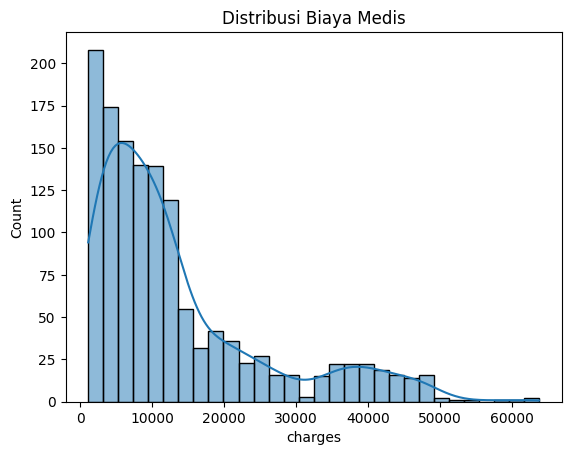

In [13]:
# Distribusi target
sns.histplot(dataset['charges'], bins=30, kde=True)
plt.title('Distribusi Biaya Medis')
plt.show()

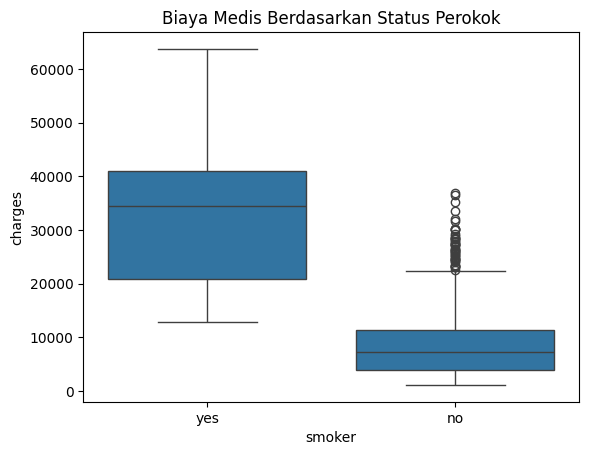

In [14]:
# Perokok vs bukan perokok
sns.boxplot(x='smoker', y='charges', data=dataset)
plt.title('Biaya Medis Berdasarkan Status Perokok')
plt.show()

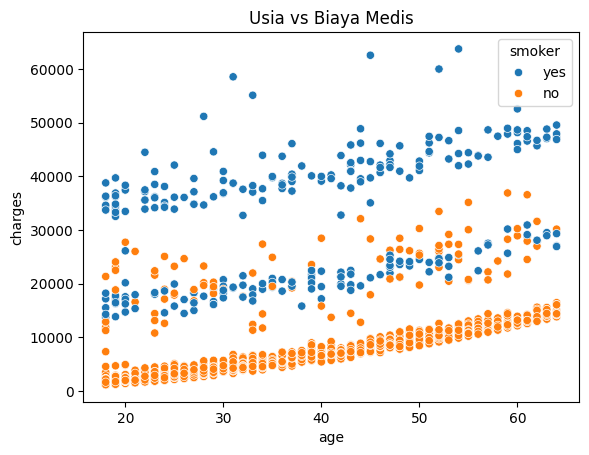

In [15]:
# Usia vs biaya, dibedakan status perokok
sns.scatterplot(x='age', y='charges', hue='smoker', data=dataset)
plt.title('Usia vs Biaya Medis')
plt.show()

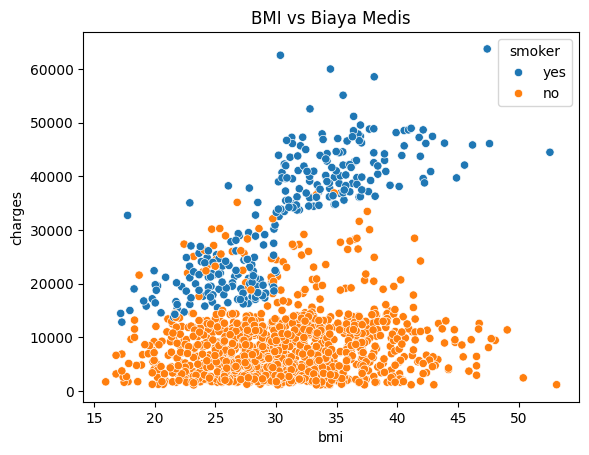

In [16]:
# BMI vs biaya, dibedakan status perokok
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=dataset)
plt.title('BMI vs Biaya Medis')
plt.show()

### **Encoding variabel kategorikal**

In [17]:
# sex, smoker, region berupa teks, jadi diubah ke angka (one-hot encoding)
data_encoded = pd.get_dummies(dataset, columns=['sex', 'smoker', 'region'], drop_first=True)
print(data_encoded.head())

   age     bmi  children      charges  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0  16884.92400     False        True             False   
1   18  33.770         1   1725.55230      True       False             False   
2   28  33.000         3   4449.46200      True       False             False   
3   33  22.705         0  21984.47061      True       False              True   
4   32  28.880         0   3866.85520      True       False              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False  
2              True             False  
3             False             False  
4             False             False  


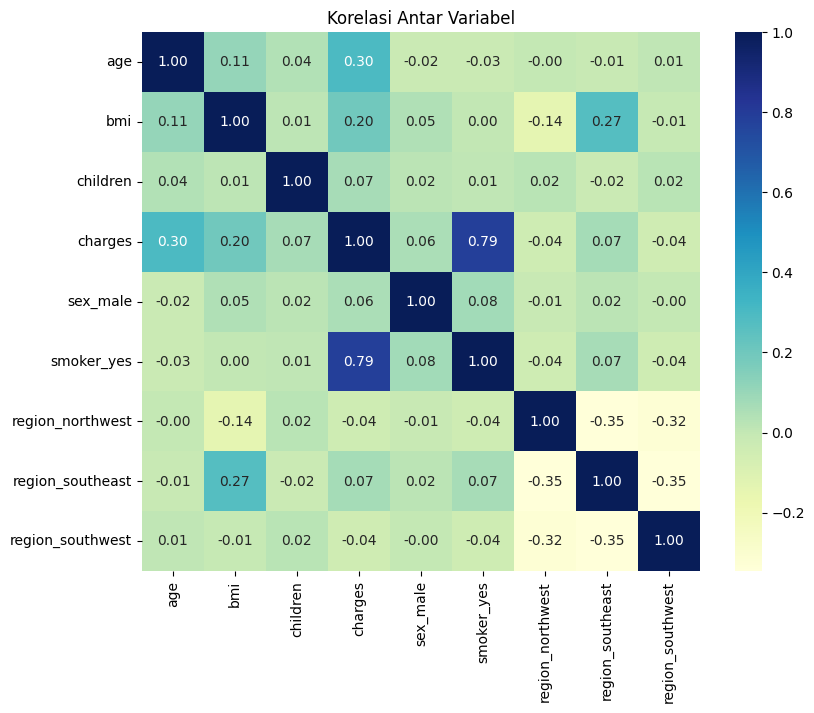

In [18]:
# Heatmap korelasi setelah encoding
plt.figure(figsize=(9, 7))
sns.heatmap(data_encoded.corr(), cmap="YlGnBu", annot=True, fmt=".2f")
plt.title('Korelasi Antar Variabel')
plt.show()

### **Tentukan fitur (X) dan target (y)**

In [19]:
X = data_encoded.drop('charges', axis=1)
y = data_encoded['charges']

### **Split data latih & uji (80:20)**

In [20]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Data latih:", X_train.shape, "| Data uji:", X_test.shape)

Data latih: (1070, 8) | Data uji: (268, 8)


### **Feature scaling (hanya kolom numerik)**

In [21]:
from sklearn.preprocessing import StandardScaler
kolom_num = ['age', 'bmi', 'children']
scaler = StandardScaler()

X_train_sc = X_train.copy()
X_test_sc = X_test.copy()
X_train_sc[kolom_num] = scaler.fit_transform(X_train[kolom_num])   # fit hanya di data latih
X_test_sc[kolom_num] = scaler.transform(X_test[kolom_num])

### **Buat & latih model**

In [22]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train_sc, y_train)

LinearRegression()

## **Prediksi data uji**

In [23]:
y_pred = model.predict(X_test_sc)

### **Evaluasi**

In [24]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)

print("R-squared:", r2)
print("MSE      :", mse)
print("RMSE     :", rmse)
print("MAE      :", mae)

# Pembanding: performa pada data latih
print("R-squared data latih:", model.score(X_train_sc, y_train))

R-squared: 0.7835929767120722
MSE      : 33596915.85136148
RMSE     : 5796.284659276275
MAE      : 4181.194473753652
R-squared data latih: 0.7417255854683333


### **Koefisien model**

In [25]:
koef = pd.DataFrame({'Fitur': X.columns, 'Koefisien': model.coef_})
print("Intercept:", model.intercept_)
print(koef.sort_values('Koefisien', key=abs, ascending=False))

Intercept: 8955.244801502879
              Fitur     Koefisien
4        smoker_yes  23651.128856
0               age   3614.975415
1               bmi   2036.228123
7  region_southwest   -809.799354
6  region_southeast   -657.864297
2          children    516.890247
5  region_northwest   -370.677326
3          sex_male    -18.591692


### **Visualisasi hasil**

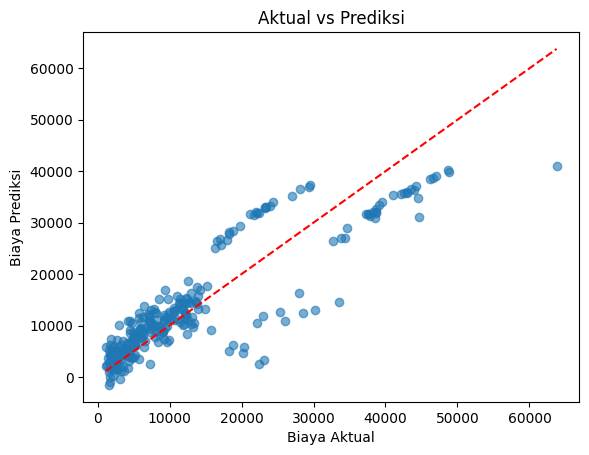

In [26]:
# Aktual vs prediksi
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Biaya Aktual')
plt.ylabel('Biaya Prediksi')
plt.title('Aktual vs Prediksi')
plt.show()

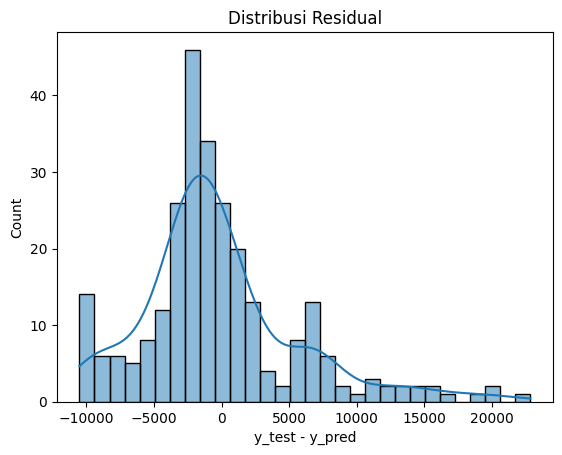

In [27]:
# Distribusi residual
residual = y_test - y_pred
sns.histplot(residual, bins=30, kde=True)
plt.title('Distribusi Residual')
plt.xlabel('y_test - y_pred')
plt.show()